In [26]:
import torch
print(torch.__version__) # to avoid DLL error

2.14.1+cpu


# Load and clean data

In [27]:
import pandas as pd

In [28]:
df = pd.read_csv("application_train.csv")

In [29]:
df.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [30]:
df.shape

(307511, 122)

In [31]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 122 entries, SK_ID_CURR to AMT_REQ_CREDIT_BUREAU_YEAR
dtypes: float64(65), int64(41), object(16)
memory usage: 286.2+ MB


In [32]:
print(df["TARGET"].value_counts())
print(df["TARGET"].value_counts(normalize=True)*100)

TARGET
0    282686
1     24825
Name: count, dtype: int64
TARGET
0    91.927118
1     8.072882
Name: proportion, dtype: float64


In [33]:
missing = (df.isnull().mean()*100).sort_values(ascending = False)
print(missing.head(20))

COMMONAREA_AVG              69.872297
COMMONAREA_MODE             69.872297
COMMONAREA_MEDI             69.872297
NONLIVINGAPARTMENTS_MEDI    69.432963
NONLIVINGAPARTMENTS_MODE    69.432963
NONLIVINGAPARTMENTS_AVG     69.432963
FONDKAPREMONT_MODE          68.386172
LIVINGAPARTMENTS_AVG        68.354953
LIVINGAPARTMENTS_MEDI       68.354953
LIVINGAPARTMENTS_MODE       68.354953
FLOORSMIN_MODE              67.848630
FLOORSMIN_AVG               67.848630
FLOORSMIN_MEDI              67.848630
YEARS_BUILD_AVG             66.497784
YEARS_BUILD_MODE            66.497784
YEARS_BUILD_MEDI            66.497784
OWN_CAR_AGE                 65.990810
LANDAREA_MEDI               59.376738
LANDAREA_AVG                59.376738
LANDAREA_MODE               59.376738
dtype: float64


In [34]:
#  Missing percentage for every column
missing = df.isnull().mean() * 100

# Keep only the columns with more than 60% missing
high_missing = missing[missing > 60]

print(high_missing.index.tolist())
print(len(high_missing))

['OWN_CAR_AGE', 'YEARS_BUILD_AVG', 'COMMONAREA_AVG', 'FLOORSMIN_AVG', 'LIVINGAPARTMENTS_AVG', 'NONLIVINGAPARTMENTS_AVG', 'YEARS_BUILD_MODE', 'COMMONAREA_MODE', 'FLOORSMIN_MODE', 'LIVINGAPARTMENTS_MODE', 'NONLIVINGAPARTMENTS_MODE', 'YEARS_BUILD_MEDI', 'COMMONAREA_MEDI', 'FLOORSMIN_MEDI', 'LIVINGAPARTMENTS_MEDI', 'NONLIVINGAPARTMENTS_MEDI', 'FONDKAPREMONT_MODE']
17


In [35]:
df = df.drop(columns = high_missing.index)
df.shape

(307511, 105)

In [36]:
num_cls = df.select_dtypes(include ="number").columns
cat_cls = df.select_dtypes(include = "object").columns
len(cat_cls)

15

In [37]:
X = df.drop(columns = ["SK_ID_CURR","TARGET"])
X.shape

(307511, 103)

In [38]:
y = df["TARGET"]
y.shape

(307511,)

In [39]:
X.head()


,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,Unaccompanied,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,Family,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,Unaccompanied,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,297000.0,Unaccompanied,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,513000.0,Unaccompanied,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [40]:
from sklearn.model_selection import train_test_split 
X_train ,X_test,  y_train ,y_test = train_test_split(X , y , test_size = 0.2 , stratify = y , random_state = 42)

In [41]:
num_cols = X_train.select_dtypes(include="number").columns
cat_cols = X_train.select_dtypes(include="object").columns

num_medians = X_train[num_cols].median()
cat_modes = X_train[cat_cols].mode().iloc[0]  

X_train[num_cols] = X_train[num_cols].fillna(num_medians)
X_test[num_cols] = X_test[num_cols].fillna(num_medians)
X_train[cat_cols] = X_train[cat_cols].fillna(cat_modes)
X_test[cat_cols] = X_test[cat_cols].fillna(cat_modes)


# One-hot encode 
X_train = pd.get_dummies(X_train, columns=cat_cols, drop_first=True, dtype=int)
X_test = pd.get_dummies(X_test, columns=cat_cols, drop_first=True, dtype=int)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

In [42]:

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaler.fit(X_train)
X_train_scaled = pd.DataFrame(scaler.transform(X_train),
                              columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test),
                             columns=X_test.columns, index=X_test.index)

In [43]:
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train_scaled, y_train)

# Logistic Regression

In [44]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, classification_report,
                             confusion_matrix, precision_score, recall_score)

log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_bal, y_train_bal)

# 10. Evaluate on the real, untouched test set
y_pred = log_reg.predict(X_test_scaled)
y_prob = log_reg.predict_proba(X_test_scaled)[:, 1]

print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall   :", round(recall_score(y_test, y_pred), 4))
print("\nConfusion matrix:\n", confusion_matrix(y_test, y_pred))
print("\n", classification_report(y_test, y_pred))

ROC-AUC  : 0.7419
Precision: 0.1623
Recall   : 0.6592

Confusion matrix:
 [[39639 16899]
 [ 1692  3273]]

               precision    recall  f1-score   support

           0       0.96      0.70      0.81     56538
           1       0.16      0.66      0.26      4965

    accuracy                           0.70     61503
   macro avg       0.56      0.68      0.54     61503
weighted avg       0.89      0.70      0.77     61503



# KNN

In [45]:
from sklearn.neighbors import KNeighborsClassifier
def evaluate(model, name):
    y_pred = model.predict(X_test_scaled)
    y_prob = model.predict_proba(X_test_scaled)[:, 1]
    print(name)
    print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob), 4))
    print("Precision:", round(precision_score(y_test, y_pred), 4))
    print("Recall   :", round(recall_score(y_test, y_pred), 4))

# take a stratified sample of 40,000 training rows
X_knn, _, y_knn, _ = train_test_split(
    X_train_scaled, y_train, train_size=40000,
    stratify=y_train, random_state=42
)

knn = KNeighborsClassifier(n_neighbors=50, n_jobs=-1)
knn.fit(X_knn, y_knn)
evaluate(knn, "KNN (40k sample)")


KNN (40k sample)
ROC-AUC  : 0.6226
Precision: 0.0
Recall   : 0.0


C:\Users\Basav\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


# naive

In [46]:
from sklearn.naive_bayes import GaussianNB

nb = GaussianNB()
nb.fit(X_train_scaled, y_train)
evaluate(nb, "Naive Bayes")

Naive Bayes
ROC-AUC  : 0.5159
Precision: 0.0822
Recall   : 0.9823


# Desision Tres

In [47]:
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(max_depth=5, random_state=42)
tree.fit(X_train_bal, y_train_bal)
evaluate(tree, "Decision Tree")

Decision Tree
ROC-AUC  : 0.6536
Precision: 0.1544
Recall   : 0.37


# Random Forest

In [48]:
from sklearn.ensemble import RandomForestClassifier
rf2 = RandomForestClassifier(n_estimators=100, max_depth=10,
                             class_weight="balanced_subsample",
                             n_jobs=-1, random_state=42)
rf2.fit(X_train_scaled, y_train)      # real, imbalanced training data
evaluate(rf2, "Random Forest (class_weight)")

Random Forest (class_weight)
ROC-AUC  : 0.7318
Precision: 0.1641
Recall   : 0.6151


# XGBooat

In [49]:
from xgboost import XGBClassifier

ratio = (y_train == 0).sum() / (y_train == 1).sum()
print("scale_pos_weight:", round(ratio, 2))

xgb = XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                    scale_pos_weight=ratio, n_jobs=-1, random_state=42,
                    eval_metric="auc")
xgb.fit(X_train_scaled, y_train)
evaluate(xgb, "XGBoost")

scale_pos_weight: 11.39
XGBoost
ROC-AUC  : 0.7584
Precision: 0.1671
Recall   : 0.681


# ANN

In [50]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)

#  Hold out 10% of train for validation
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_scaled, y_train, test_size=0.1, stratify=y_train, random_state=42
)

#  Convert to tensors
def to_t(X, y=None):
    Xt = torch.tensor(X.values.astype("float32"))
    return Xt if y is None else (Xt, torch.tensor(y.values.astype("float32")).unsqueeze(1))

Xtr_t, ytr_t = to_t(X_tr, y_tr)
Xval_t = to_t(X_val)
Xte_t = to_t(X_test_scaled)

loader = DataLoader(TensorDataset(Xtr_t, ytr_t), batch_size=512, shuffle=True)

#  The network
model = nn.Sequential(
    nn.Linear(Xtr_t.shape[1], 128), nn.ReLU(), nn.Dropout(0.3),
    nn.Linear(128, 64), nn.ReLU(), nn.Dropout(0.3),
    nn.Linear(64, 1)
)

loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([ratio], dtype=torch.float32))
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

# Training loop
best_auc, best_state = 0, None
for epoch in range(15):
    model.train()
    for xb, yb in loader:
        optimizer.zero_grad()
        loss = loss_fn(model(xb), yb)
        loss.backward()
        optimizer.step()

    model.eval()
    with torch.no_grad():
        val_prob = torch.sigmoid(model(Xval_t)).numpy().ravel()
    auc = roc_auc_score(y_val, val_prob)
    print(f"Epoch {epoch+1:2d}  val ROC-AUC: {auc:.4f}")
    if auc > best_auc:
        best_auc = auc
        best_state = {k: v.clone() for k, v in model.state_dict().items()}

#  Load the best epoch and test once
model.load_state_dict(best_state)
model.eval()
with torch.no_grad():
    y_prob = torch.sigmoid(model(Xte_t)).numpy().ravel()
y_pred = (y_prob > 0.5).astype(int)

print("\nANN (PyTorch)")
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall   :", round(recall_score(y_test, y_pred), 4))

Epoch  1  val ROC-AUC: 0.7364
Epoch  2  val ROC-AUC: 0.7383
Epoch  3  val ROC-AUC: 0.7402
Epoch  4  val ROC-AUC: 0.7399
Epoch  5  val ROC-AUC: 0.7385
Epoch  6  val ROC-AUC: 0.7377
Epoch  7  val ROC-AUC: 0.7387
Epoch  8  val ROC-AUC: 0.7365
Epoch  9  val ROC-AUC: 0.7370
Epoch 10  val ROC-AUC: 0.7360
Epoch 11  val ROC-AUC: 0.7366
Epoch 12  val ROC-AUC: 0.7365
Epoch 13  val ROC-AUC: 0.7355
Epoch 14  val ROC-AUC: 0.7348
Epoch 15  val ROC-AUC: 0.7350

ANN (PyTorch)
ROC-AUC  : 0.7452
Precision: 0.1507
Recall   : 0.711


# Tuning

In [51]:
from sklearn.model_selection import RandomizedSearchCV

param_grid = {
    "n_estimators": [200, 300, 500],
    "learning_rate": [0.03, 0.05, 0.1],
    "max_depth": [3, 4, 5, 6],
    "subsample": [0.7, 0.85, 1.0],
    "colsample_bytree": [0.5, 0.7, 1.0],
}

base_xgb = XGBClassifier(scale_pos_weight=ratio, tree_method="hist",
                         n_jobs=-1, random_state=42, eval_metric="auc")

search = RandomizedSearchCV(base_xgb, param_grid, n_iter=8, scoring="roc_auc",
                            cv=3, random_state=42, verbose=1)
search.fit(X_train_scaled, y_train)   # real training data only

print("Best CV ROC-AUC:", round(search.best_score_, 4))
print("Best settings  :", search.best_params_)

best_xgb = search.best_estimator_
evaluate(best_xgb, "XGBoost (tuned)")

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best CV ROC-AUC: 0.7552
Best settings  : {'subsample': 0.7, 'n_estimators': 500, 'max_depth': 5, 'learning_rate': 0.03, 'colsample_bytree': 0.7}
XGBoost (tuned)
ROC-AUC  : 0.7615
Precision: 0.171
Recall   : 0.6677


In [52]:

y_prob = knn.predict_proba(X_test_scaled)[:, 1]

for t in [0.05, 0.08, 0.10, 0.15]:
    pred_t = (y_prob >= t).astype(int)
    print(t, "precision:", round(precision_score(y_test, pred_t, zero_division=0), 3),
             "recall:", round(recall_score(y_test, pred_t), 3))

0.05 precision: 0.095 recall: 0.814
0.08 precision: 0.105 recall: 0.682
0.1 precision: 0.117 recall: 0.536
0.15 precision: 0.157 recall: 0.176


In [53]:
from xgboost import XGBClassifier
import shap

xgb = XGBClassifier(n_estimators=500, learning_rate=0.03, max_depth=5,
                    subsample=0.7, colsample_bytree=0.7,
                    scale_pos_weight=ratio, tree_method="hist",
                    n_jobs=-1, random_state=42, eval_metric="auc")
xgb.fit(X_train_scaled, y_train)

y_prob = xgb.predict_proba(X_test_scaled)[:, 1]
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

ROC-AUC: 0.7615


# PCA and K-Means

In [54]:
from sklearn.decomposition import PCA

pca = PCA(n_components=0.90, random_state=42)   # keep 90% of the information
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Columns before:", X_train_scaled.shape[1])
print("Columns after :", X_train_pca.shape[1])

Columns before: 209
Columns after : 140


In [55]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=4, n_init=5, random_state=42)
train_clusters = kmeans.fit_predict(X_train_pca)

# Default rate in each cluster
result = pd.DataFrame({"cluster": train_clusters, "default": y_train.values})
summary = result.groupby("cluster")["default"].agg(["count", "mean"])
print(summary.round(4))


          count    mean
cluster                
0          6538  0.0552
1         40827  0.0544
2         27315  0.0570
3        171328  0.0918


# shap

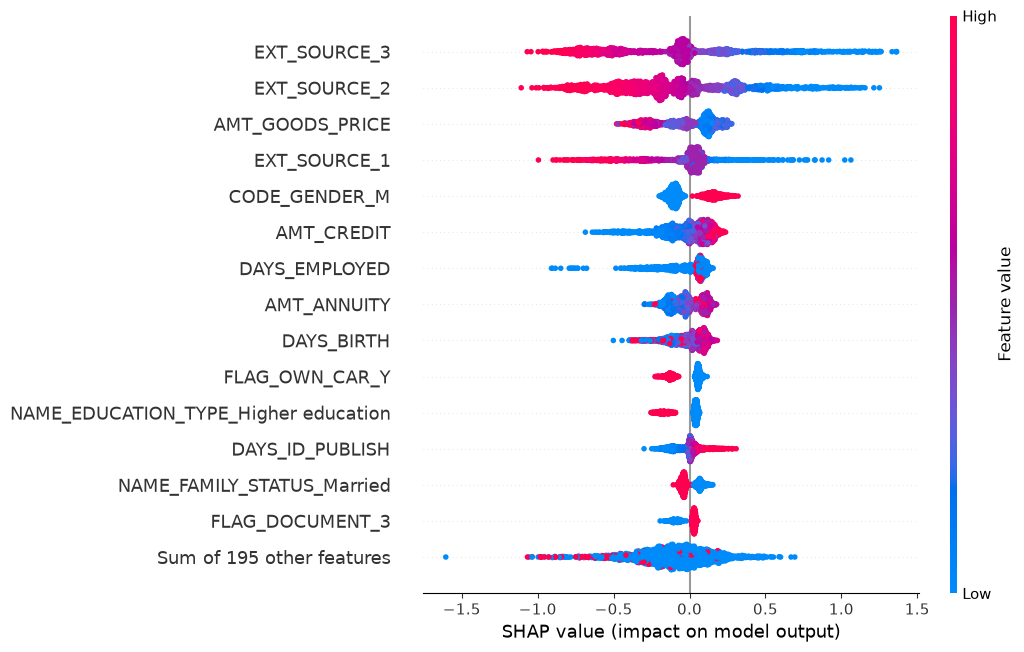

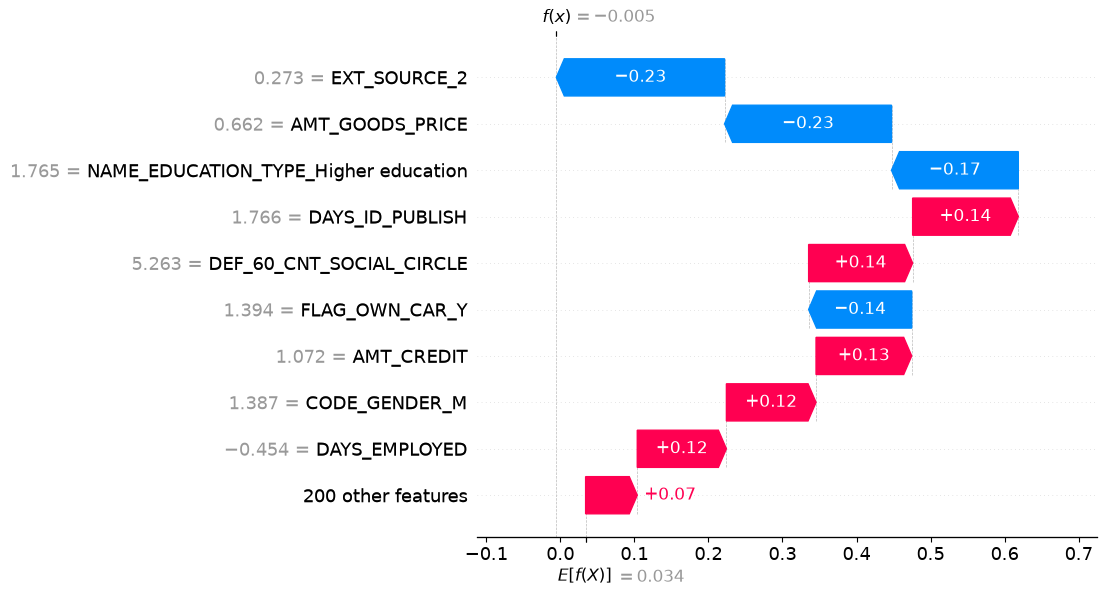

In [60]:
import shap

# SHAP on all 61,503 rows is slow, so use a random sample of 2,000
sample = X_test_scaled.sample(2000, random_state=42)

explainer = shap.TreeExplainer(xgb)
shap_values = explainer(sample)

# Global view: which columns matter most, and in which direction
shap.plots.beeswarm(shap_values, max_display=15)

# One applicant: why did the model score this person this way?
shap.plots.waterfall(shap_values[0])

# save the model

In [57]:
import joblib, os

os.makedirs("credit_api", exist_ok=True)

artifacts = {
    "model": xgb,
    "scaler": scaler,
    "num_cols": list(num_cols),
    "cat_cols": list(cat_cols),
    "num_medians": num_medians.to_dict(),
    "cat_modes": cat_modes.to_dict(),
    "model_columns": list(X_train.columns),
}

joblib.dump(artifacts, "credit_api/model_artifacts.joblib")

print(len(num_cols), len(cat_cols), len(X_train.columns))

88 15 209


In [58]:
print(df.iloc[[0]].drop(columns=["TARGET", "SK_ID_CURR"]).dropna(axis=1).to_json(orient="records")[1:-1])

{"NAME_CONTRACT_TYPE":"Cash loans","CODE_GENDER":"M","FLAG_OWN_CAR":"N","FLAG_OWN_REALTY":"Y","CNT_CHILDREN":0,"AMT_INCOME_TOTAL":202500.0,"AMT_CREDIT":406597.5,"AMT_ANNUITY":24700.5,"AMT_GOODS_PRICE":351000.0,"NAME_TYPE_SUITE":"Unaccompanied","NAME_INCOME_TYPE":"Working","NAME_EDUCATION_TYPE":"Secondary \/ secondary special","NAME_FAMILY_STATUS":"Single \/ not married","NAME_HOUSING_TYPE":"House \/ apartment","REGION_POPULATION_RELATIVE":0.018801,"DAYS_BIRTH":-9461,"DAYS_EMPLOYED":-637,"DAYS_REGISTRATION":-3648.0,"DAYS_ID_PUBLISH":-2120,"FLAG_MOBIL":1,"FLAG_EMP_PHONE":1,"FLAG_WORK_PHONE":0,"FLAG_CONT_MOBILE":1,"FLAG_PHONE":1,"FLAG_EMAIL":0,"OCCUPATION_TYPE":"Laborers","CNT_FAM_MEMBERS":1.0,"REGION_RATING_CLIENT":2,"REGION_RATING_CLIENT_W_CITY":2,"WEEKDAY_APPR_PROCESS_START":"WEDNESDAY","HOUR_APPR_PROCESS_START":10,"REG_REGION_NOT_LIVE_REGION":0,"REG_REGION_NOT_WORK_REGION":0,"LIVE_REGION_NOT_WORK_REGION":0,"REG_CITY_NOT_LIVE_CITY":0,"REG_CITY_NOT_WORK_CITY":0,"LIVE_CITY_NOT_WORK_CITY"

In [61]:
import xgboost, sklearn, pandas, numpy, shap, torch, imblearn
print("xgboost==" + xgboost.__version__)
print("scikit-learn==" + sklearn.__version__)
print("pandas==" + pandas.__version__)
print("numpy==" + numpy.__version__)
print("shap==" + shap.__version__)
print("imbalanced-learn==" + imblearn.__version__)
print("torch==" + torch.__version__.split("+")[0])

xgboost==3.4.1
scikit-learn==1.9.0
pandas==2.2.3
numpy==2.2.1
shap==0.54.1
imbalanced-learn==0.14.2
torch==2.14.1
